## Project: Forecasting El Niño - could the super El Niño have been predicted?
#### Author: E. Provenzano (LOCEAN-IPSL)

El Niño-Southern Oscillation (**ENSO**) is the leading mode of year-to-year climate variability on the planet.
It is a *coupled* ocean-atmosphere phenomenon of the equatorial Pacific:

- **Ocean side.** During an El Niño, the trade winds weaken and a tongue of anomalously warm water spreads across the central and eastern equatorial Pacific (sea surface temperature, **SST**).
- **Atmosphere side.** The warming reorganises tropical convection and the **Walker circulation**, which shows up as a see-saw in **sea-level pressure (SLP)** between the western and eastern Pacific (the *Southern Oscillation*).


<img alt="weather" src="images/ENSO-normal.png" width=400 style="float:left">
<img alt="weather" src="images/ENSO-El_Nino.png" width=400 style="float:right">

Because the two components are coupled, ENSO has some intrinsic **predictability** - but that predictability is limited, and it is famously hardest to forecast *through boreal spring* (the **spring predictability barrier**).

<div class="alert alert-block alert-success">
<b>Why this project is timely.</b> A strong El Niño is developing <b>right now</b> (2026-27) and forecast centres consider it likely to reach <b>"super" El Niño</b> intensity around the end of 2026. 
This gives you a live case study: <b>starting from the situation in early 2026, could a model have anticipated the event?</b> You can also validate the same approach on the fully-observed super events of 1997–98, 2015–16 and 2023–24.
</div>

### The problem

> **Target.** The Oceanic Niño Index (**ONI**): the 3-month running mean of the SST anomaly averaged over the **Niño 3.4** box (5°S-5°N, 170°W-120°W).
>
> **Task.** Given information available up to month *t*, predict the ONI at month *t + τ* for a chosen **lead time** τ (e.g. 3, 6, 9, 12 months). Equivalently, predict the ENSO **phase** (El Niño / Neutral / La Niña) at *t + τ* as a classification problem.
>
> **Case study.** Focus the evaluation on the **super El Niño** events. Could the model have called the 2026-27 event from early-2026 initial conditions? How well does it hindcast 1997-98, 2015-16, 2023-24?

Making a *prediction* here means: fit the model **only** on data before the period you are forecasting, then compare its forecast to what actually happened. A forecast is only meaningful relative to a **baseline**. Baselines could be, for instance, **persistence** (assume the ONI stays at its current value) or **climatology** (assume ONI = 0).

### Data set: ERA5 monthly reanalysis (1940-2026)
We use the **ERA5 monthly averaged reanalysis** from the Copernicus Climate Data Store (CDS), which spans **1940 to the present**. 
>Copernicus Climate Change Service (2023): ERA5 monthly averaged data on single levels from 1940 to present. Copernicus Climate Change Service (C3S) Climate Data Store (CDS). DOI: 10.24381/cds.f17050d7 

Two single-level variables:

| Variable | ERA5 short name | Units | Role |
|---|---|---|---|
| Sea surface temperature | `sst` | K | Ocean side → Niño 3.4 / ONI, the **target** |
| Mean sea-level pressure | `msl` | Pa | Atmosphere side → Southern Oscillation Index (**SOI**), a **predictor** |

- **Temporal resolution:** monthly mean, 1940-01 to the latest available month (ERA5 monthly means lag
  real time by ~2–3 months, so by autumn 2026 the record typically runs to around mid-2026; use whatever
  is latest).
- **Spatial resolution:** 0.25°×0.25° native.
- **Selected region:** 5°S-5°N, 170°W-120°W (Niño 3.4 box)

#### Load the data

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset("./data/era5_sst_msl_monthly_1940_2026.nc")

### Step 1 - Characterise El Niño from the ocean (SST → ONI)

The official ENSO yardstick is the **ONI**: take the SST anomaly averaged over the Niño 3.4 box, then smooth with a 3-month running mean.

- **El Niño** when ONI ≥ **+0.5 °C**, **La Niña** when ONI ≤ **−0.5 °C**, otherwise **Neutral**
- A **"super" El Niño** is one whose peak ONI reaches **+2.0 °C**.

In [2]:
# --- helper functions ------------------------------------------------------------
def area_weighted_mean(da, lat0, lat1, lon0, lon1):
    """Cosine-latitude-weighted mean over a lon/lat box"""
    sub = da.sel(latitude=slice(lat0, lat1), longitude=slice(lon0, lon1))
    w = np.cos(np.deg2rad(sub.latitude))
    return sub.weighted(w).mean(("latitude", "longitude"))

def monthly_anomaly(ts, base=("1940", "2026")):
    clim = ts.sel(time=slice(*base)).groupby("time.month").mean("time")
    return ts.groupby("time.month") - clim

def running_mean(ts, n=3):
    return ts.rolling(time=n, center=True).mean()

# --- Niño 3.4 SST index and ONI --------------------------------------------------
sst_c   = ds["sst"] - 273.15                              # K -> °C
nino34  = area_weighted_mean(sst_c, -5, 5, 190, 240)      # 170°W–120°W = 190°E–240°E
nino34_anom = monthly_anomaly(nino34)
oni = running_mean(nino34_anom, 3).rename("ONI")

# --- classify the phase ----------------------------------------------------------
phase = xr.where(oni >= 0.5, "El Nino",
         xr.where(oni <= -0.5, "La Nina", "Neutral")).rename("phase")
is_super = (oni >= 2.0)
print("Number of months classified 'super' (ONI >= +2.0):", int(is_super.sum()))

Number of months classified 'super' (ONI >= +2.0): 20


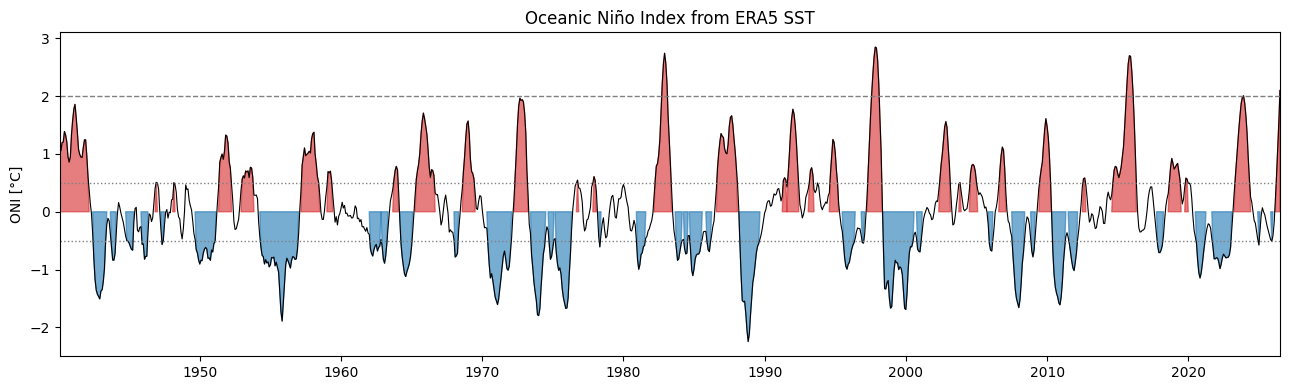

In [3]:
# Plot the ONI with the classic +/-0.5 and +2.0 thresholds
fig, ax = plt.subplots(figsize=(13, 4))
t = oni.time
ax.fill_between(t, 0, oni, where=(oni >= 0.5),  color="tab:red",  alpha=.6, interpolate=True)
ax.fill_between(t, 0, oni, where=(oni <= -0.5), color="tab:blue", alpha=.6, interpolate=True)
ax.plot(t, oni, color="k", lw=.8)
for thr, ls in [(0.5, ":"), (-0.5, ":"), (2.0, "--")]:
    ax.axhline(thr, color="grey", ls=ls, lw=1)
ax.set_ylabel("ONI [°C]"); ax.set_title("Oceanic Niño Index from ERA5 SST")
ax.margins(x=0)
plt.tight_layout()

### Step 2 - The atmospheric side (SLP → Southern Oscillation Index)

ENSO is *coupled*, so the ocean signal has an atmospheric twin. The **Southern Oscillation Index (SOI)** measures the pressure see-saw between the western and eastern tropical Pacific. 

The classic station-based SOI uses **Tahiti minus Darwin** SLP anomalies (standardised). During El Niño the SOI goes **negative** (pressure falls at Tahiti, rises at Darwin); during La Niña it is positive.

corr(SOI, ONI) = -0.595


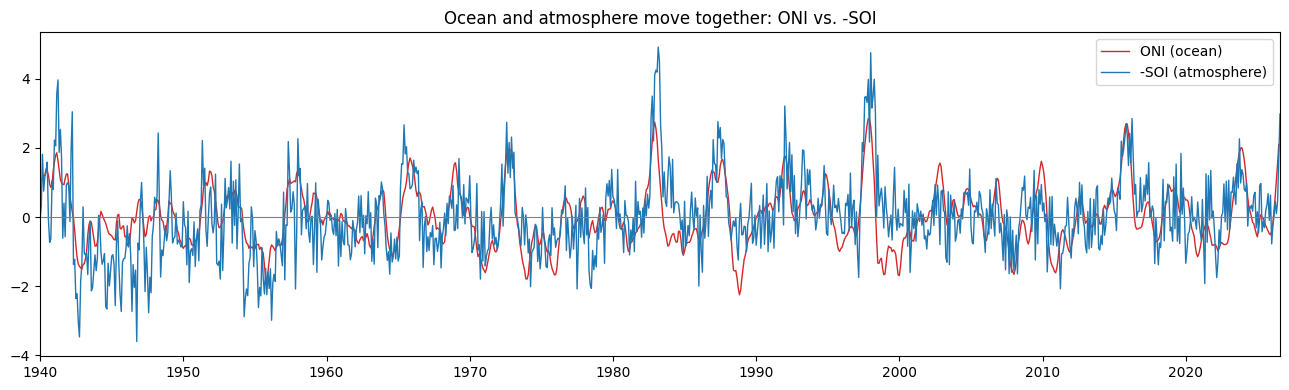

In [4]:
def standardize(ts, base=("1940", "2026")):
    m = ts.sel(time=slice(*base)).groupby("time.month").mean("time")
    s = ts.sel(time=slice(*base)).groupby("time.month").std("time")
    return xr.apply_ufunc(lambda x, mm, ss: (x - mm) / ss, ts.groupby("time.month"), m, s)

# Station-based SOI (Tahiti - Darwin), from ERA5 MSL at nearest grid points
tahiti = ds["msl"].sel(latitude=-17.5, longitude=360 - 149.4, method="nearest")
darwin = ds["msl"].sel(latitude=-12.4, longitude=130.9,       method="nearest")
soi_raw = standardize(tahiti) - standardize(darwin)
soi = (soi_raw / soi_raw.sel(time=slice("1991", "2020")).std()).rename("SOI")

print("corr(SOI, ONI) =", round(float(xr.corr(soi, oni)), 3))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(oni.time, oni, color="tab:red",  lw=1, label="ONI (ocean)")
ax.plot(soi.time, -soi, color="tab:blue", lw=1, label="-SOI (atmosphere)")
ax.axhline(0, color="grey", lw=.8); ax.margins(x=0)
ax.set_title("Ocean and atmosphere move together: ONI vs. -SOI")
ax.legend(); plt.tight_layout()

### Step 3 - What does it mean to *make a prediction*?

Turn the time series into a **supervised learning** problem:

- **Features** at month *t*: recent values (lags) of the ocean index (Niño 3.4 anomaly) and the atmospheric index (SOI).
- **Label**: the ONI at month *t + τ*.
- **Split**: train on the early record, test on the recent record — **never** let information from the forecast period leak into training. 
- **Baselines**: *persistence* (ONI at *t + τ* ≈ ONI at *t*) and *climatology* (ONI = 0). Report skill as RMSE and correlation.

### Case study: could the super El Niño be predicted?

<div class="alert alert-block alert-info">
<b>Guiding questions</b>

1. <b>The live one (2026-27).</b> Using only data up to a chosen "issue date" in early 2026 (e.g. Jan or Mar 2026, i.e. <i>before</i> the onset), forecast the ONI through the rest of 2026 at several lead times. Does your model reproduce the rapid warming that actually occurred? At what issue date does the signal first appear?
2. <b>Validation on observed super events.</b> Repeat the exercise for 1997–98, 2015–16 and 2023–24,
   each time training only on data <i>before</i> that event. Are some easier to predict than others?
3. <b>Ocean vs. atmosphere.</b> Does adding SLP/SOI predictors improve the early forecasts over SST-only? 
4. <b>Phase vs. amplitude.</b> Is it easier to predict the <i>phase</i> (a classifier: El Niño / Neutral / La Niña) than the exact ONI value (regression)?
5. <b>The barrier.</b> Quantify how skill drops for forecasts crossing boreal spring. </div>

### Going further: methods to try

You are free to choose the method(s); justify them, and explain failures.

- **Features.** EOF/PCA of tropical-Pacific SST and SLP (reduce the maps to a few modes); other Niño
  regions (1+2, 3, 4); warm-water-volume proxies; seasonal encoding.
- **Regression models.** Ridge/Lasso (baseline and interpretable), random forests / gradient boosting, or a small LSTM / temporal CNN if you want a sequence model.
- **Classification.** Logistic regression or a random-forest classifier for the phase at lead τ; report a
  confusion matrix and compare with the regression-then-threshold approach.
- **Analogues.** A nearest-neighbour "analogue forecast": find past states most similar to the issue-date
  state and average what happened next — a strong, physically-motivated baseline.
- **Evaluation.** Skill vs. lead time; skill as a function of the target season (to expose the spring
  barrier); reliability of the probabilistic phase forecasts.

***
## Credit

[//]: # "This notebook is part of [E4C Interdisciplinary Center - Education](https://gitlab.in2p3.fr/energy4climate/public/education)."
Contributors include Bruno Deremble and Alexis Tantet.
Several slides and images are taken from the very good [Scikit-learn course](https://inria.github.io/scikit-learn-mooc/).

<br>

<div style="display: flex; height: 70px">
    
<img alt="Logo LMD" src="images/logos/logo_lmd.jpg" style="display: inline-block"/>

<img alt="Logo IPSL" src="images/logos/logo_ipsl.png" style="display: inline-block"/>

<img alt="Logo E4C" src="images/logos/logo_e4c_final.png" style="display: inline-block"/>

<img alt="Logo EP" src="images/logos/logo_ep.png" style="display: inline-block"/>

<img alt="Logo SU" src="images/logos/logo_su.png" style="display: inline-block"/>

<img alt="Logo ENS" src="images/logos/logo_ens.jpg" style="display: inline-block"/>

<img alt="Logo CNRS" src="images/logos/logo_cnrs.png" style="display: inline-block"/>
    
</div>

<hr>

<div style="display: flex">
    <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/"><img alt="Creative Commons License" style="border-width:0; margin-right: 10px" src="https://i.creativecommons.org/l/by-sa/4.0/88x31.png" /></a>
    <br>This work is licensed under a &nbsp; <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/">Creative Commons Attribution-ShareAlike 4.0 International License</a>.
</div>